# Домашнє завдання: Статистичні візуалізації з Seaborn

## Опис завдання
У цьому домашньому завданні ви будете використовувати бібліотеку Seaborn для створення красивих статистичних візуалізацій. Seaborn має кращий стандартний стиль та спеціалізується на статистичних графіках.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - як відчувається температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Завантаження даних
df = pd.read_csv('/content/yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Встановлюємо стиль seaborn
sns.set_theme(style="whitegrid")

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour


---

## Завдання 1: Лінійний графік з довірчими інтервалами

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно з довірчими інтервалами (confidence intervals) рівними 1 стандартному відхиленню.

**УВАГА!** В лекції ми будували подібний графік, але там були дані по номеру місяця, а тут треба зобразити дані в розрізі місяць_рік.

В якості підказки вам наведений код для створення колонки, яка містить `місяць_рік`. Як її використати - вже питання до вас :)

Очікуваний результат:
![](https://drive.google.com/uc?id=1uVKqfY1VlhVMaM3wu99uVGT1f7S0Vf8S)

**Питання для інтерпретації:**
- В які місяці найбільша невизначеність в даних?

In [2]:
df['month_year'] = df.index.to_period('M')
df['month_year']  = df.month_year.astype(str)

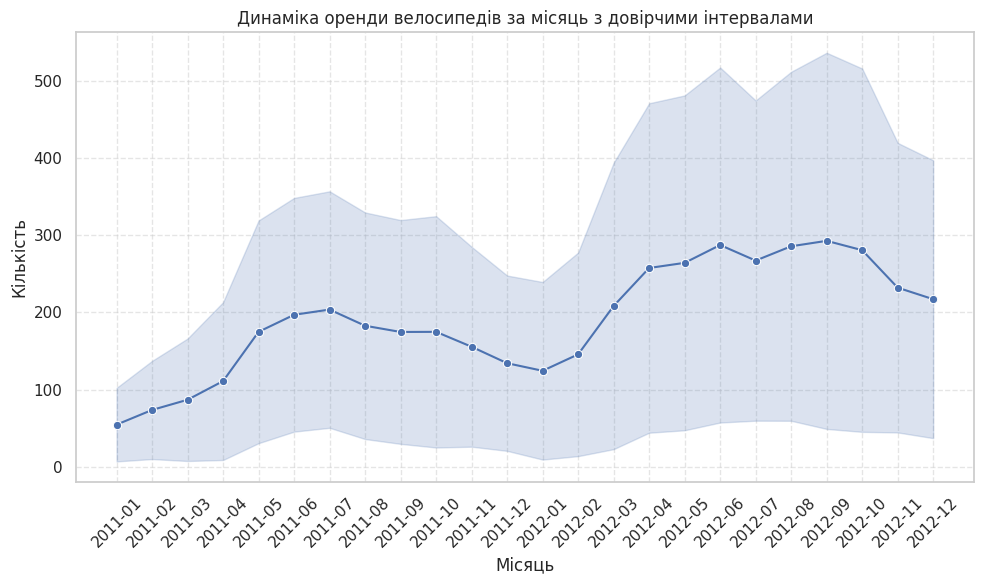

In [3]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    df,
    x= 'month_year',
    y= 'count',
    marker='o',
    errorbar='sd')

plt.title('Динаміка оренди велосипедів за місяць з довірчими інтервалами')
plt.xlabel('Місяць')
plt.ylabel('Кількість')
plt.xticks(rotation = 45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout();

## Завдання 2: Порівняння стилів - Pandas vs Seaborn гістограма

**Завдання:**
Побудуйте гістограму розподілу температури двома способами - з Pandas та Seaborn - та порівняйте візуальний вигляд. Задайте однакову кількість бінів в цих візуалізаціях, відмінну від стандартної. В візуалізації Seaborn додайте параметр при побудові `kde=True`.

**Функція Seaborn: `sns.histplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

**Дайте відповідь на питання:**
1. Яка візуальна різниця між Pandas та Seaborn гістограмами?
2. Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?

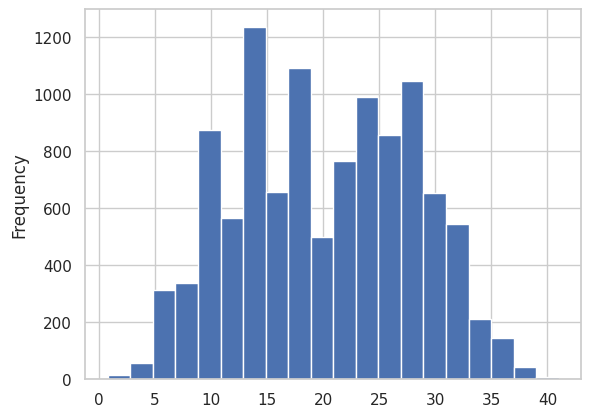

In [4]:
df['temp'].plot.hist(bins=20);

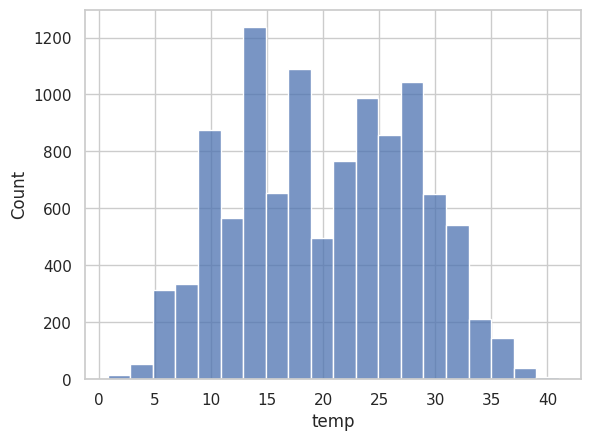

In [5]:
sns.histplot(data=df, x='temp', bins=20);

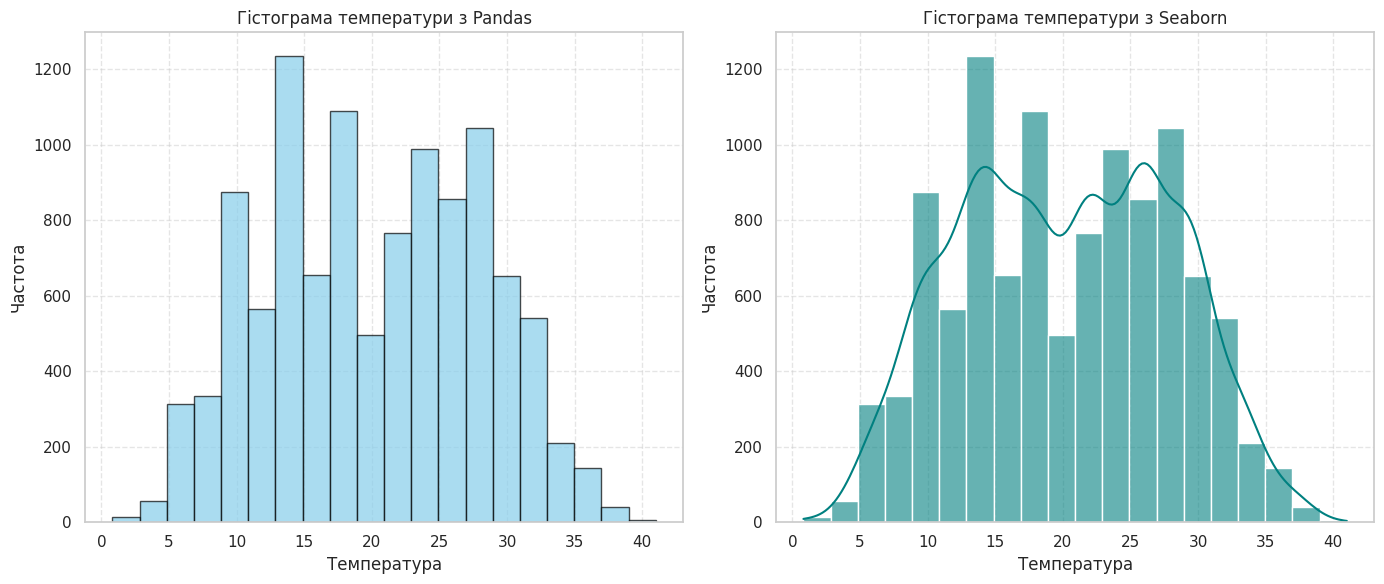

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df['temp'].plot.hist(bins=20, ax=axes[0], color='skyblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Гістограма температури з Pandas')
axes[0].set_xlabel('Температура')
axes[0].set_ylabel('Частота')
axes[0].grid(True, linestyle='--', alpha=0.5)

sns.histplot(df, x='temp', bins=20, kde=True, ax=axes[1], color='teal', alpha=0.6)
axes[1].set_title('Гістограма температури з Seaborn')
axes[1].set_xlabel('Температура')
axes[1].set_ylabel('Частота')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout();

Pandas будує просту прямолінійну гістограму без додаткових ефектів. Seaborn виглядає сучасніше і візуально красивіше, має плавніше згладжування за замовчуванням і може містити додаткові елементи.

Додаткова лінія в Seaborn - це оцінка щільності. Це плавна крива, що показує загальну форму та розподіл даних, обєднує вершини стовпчиків гістограми в єдиний тренд щільності.

## Завдання 3: Box Plot порівняння - Pandas vs Seaborn

**Завдання:**
Побудуйте box plot для кількості погодинних оренд велосипедів за погодними умовами з Pandas та Seaborn.

**Функція Seaborn: `sns.boxplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

Просунуте доповнення:
- підпишіть погодні умови їх інтерпретацією з опису даних в обох графіках

**Дайте відповідь на питання:**
- Яка візуальна різниця між Pandas та Seaborn бокс-плотами?

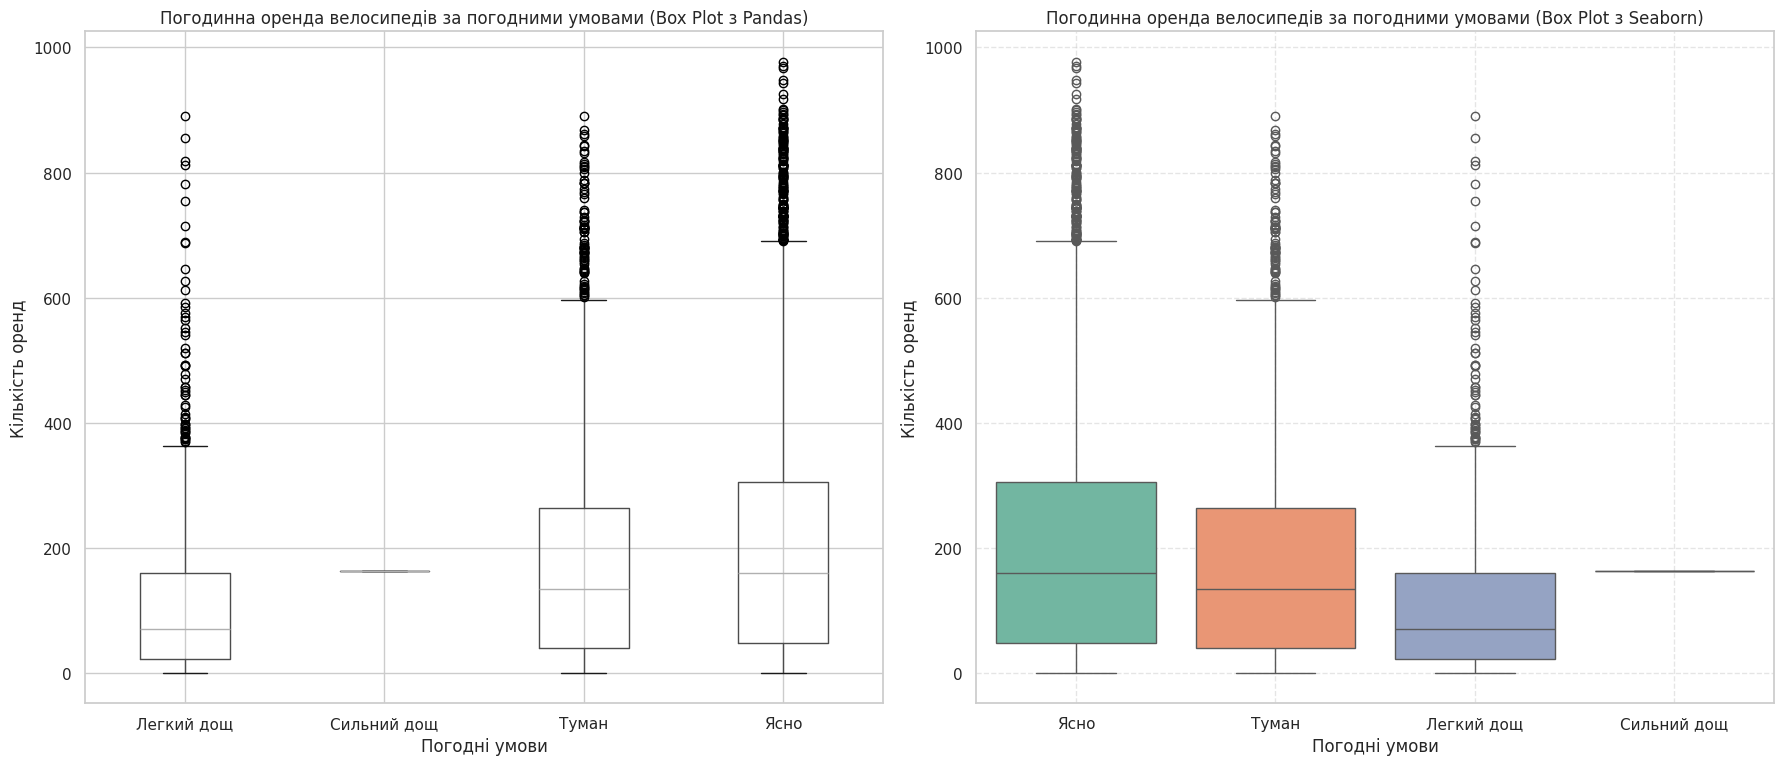

In [7]:
weather_labels = {1: 'Ясно', 2: 'Туман', 3: 'Легкий дощ', 4: 'Сильний дощ'}
df['weather_name'] = df['weather'].map(weather_labels)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

df.boxplot(column='count', by='weather_name', ax=axes[0], grid=True)
axes[0].set_title('Погодинна оренда велосипедів за погодними умовами (Box Plot з Pandas)')
axes[0].set_xlabel('Погодні умови')
axes[0].set_ylabel('Кількість оренд')

plt.suptitle('')

sns.boxplot(data=df, x='weather_name', y='count',hue='weather_name', ax=axes[1], palette='Set2')
axes[1].set_title('Погодинна оренда велосипедів за погодними умовами (Box Plot з Seaborn)')
axes[1].set_xlabel('Погодні умови')
axes[1].set_ylabel('Кількість оренд')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout();


Pandas будує базовий графік у стилі Matplotlib та він виглядає простіше. Seaborn одразу створює естетичний та симпатичний дизайн, використовує кольорову палітру, має акуратні мягкі лінії, позначки для викидів.

<!-- - -->
## Завдання 4: Heatmap кореляційної матриці

**Завдання:**
Створіть із Seaborn кореляційну матрицю з забарвленням heatmap (колір відповідає величині значення в клітинці) числових змінних в наших даних з анотаціями значень.

**Дайте відповіді на питання по графіку:**
1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)?
2. Яка кореляція між temp та atemp? Чому?
3. Які змінні мають негативну кореляцію?


In [8]:
numeric_cols = ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp','humidity', 'windspeed', 'casual', 'registered', 'count']

In [9]:
correlation = df[numeric_cols].corr()
correlation

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
season,1.000000,0.029368,-0.008126,0.008879,0.258689,0.264744,0.190610,-0.147121,0.096758,0.164011,0.163439
holiday,0.029368,1.000000,-0.250491,-0.007074,0.000295,-0.005215,0.001929,0.008409,0.043799,-0.020956,-0.005393
workingday,-0.008126,-0.250491,1.000000,0.033772,0.029966,0.024660,-0.010880,0.013373,-0.319111,0.119460,0.011594
weather,0.008879,-0.007074,0.033772,1.000000,-0.055035,-0.055376,0.406244,0.007261,-0.135918,-0.109340,-0.128655
temp,0.258689,0.000295,0.029966,-0.055035,1.000000,0.984948,-0.064949,-0.017852,0.467097,0.318571,0.394454
atemp,0.264744,-0.005215,0.024660,-0.055376,0.984948,1.000000,-0.043536,-0.057473,0.462067,0.314635,0.389784
humidity,0.190610,0.001929,-0.010880,0.406244,-0.064949,-0.043536,1.000000,-0.318607,-0.348187,-0.265458,-0.317371
windspeed,-0.147121,0.008409,0.013373,0.007261,-0.017852,-0.057473,-0.318607,1.000000,0.092276,0.091052,0.101369
casual,0.096758,0.043799,-0.319111,-0.135918,0.467097,0.462067,-0.348187,0.092276,1.000000,0.497250,0.690414
registered,0.164011,-0.020956,0.119460,-0.109340,0.318571,0.314635,-0.265458,0.091052,0.497250,1.000000,0.970948


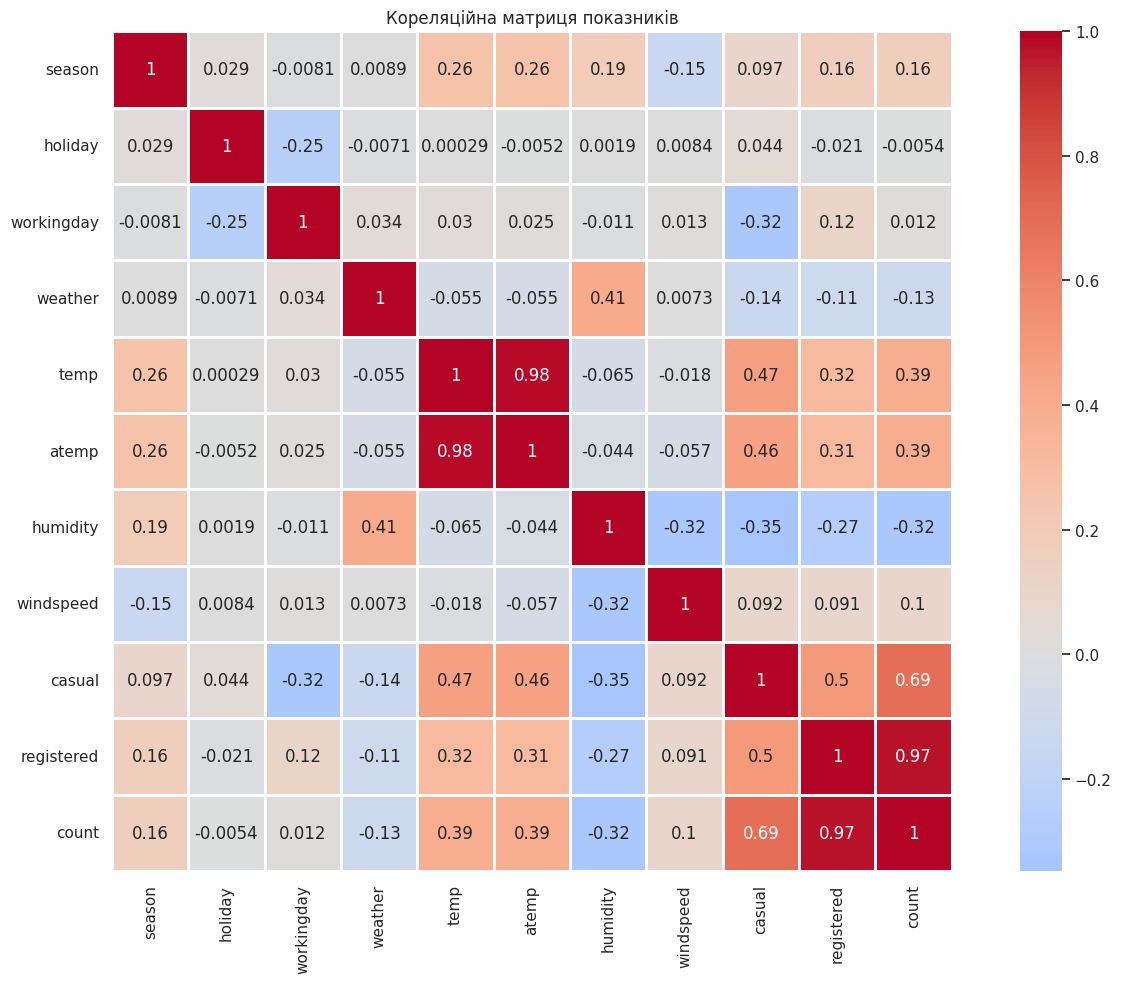

In [10]:
plt.figure(figsize=(14, 10))


sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1
            )

plt.title('Кореляційна матриця показників')
plt.tight_layout()
plt.show()

Найсильніша кореляція з count. registered 0,97, casual 0,69 та температура temp/atemp 0,39.

Кореляція між temp та atemp. 0,98 - майже ідеальна. Тому що це фактична та відчутна температура, які походять одна від одної та змінюються синхронно.

Змінні з негативною кореляцією.humidity -0,32 - підвищена вологість знижує бажання їздити на велосипеді. weather -0,13, тобто погіршення погодних умов зменшує кількість оренд. Також легкий від'ємний зв'язок є у windspeed з деякими показниками або holiday workingday залежно від перетину.

## Завдання 5: Violin Plot для глибокого аналізу розподілів

**Завдання:**
Створіть violin plot для аналізу розподілу оренди за кварталами.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показує "товщина" violin plot?
2. В якому кварталі найбільша варіабельність оренди?
3. Яка перевага violin plot над звичайним box plot?


In [11]:
df.head(3)

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,...,date,day,week,weekday_num,weekday,year,month,hour,month_year,weather_name
datetime,,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,...,2011-01-01,1,52,5,Saturday,2011,1,0,2011-01,Ясно
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,...,2011-01-01,1,52,5,Saturday,2011,1,1,2011-01,Ясно
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,...,2011-01-01,1,52,5,Saturday,2011,1,2,2011-01,Ясно


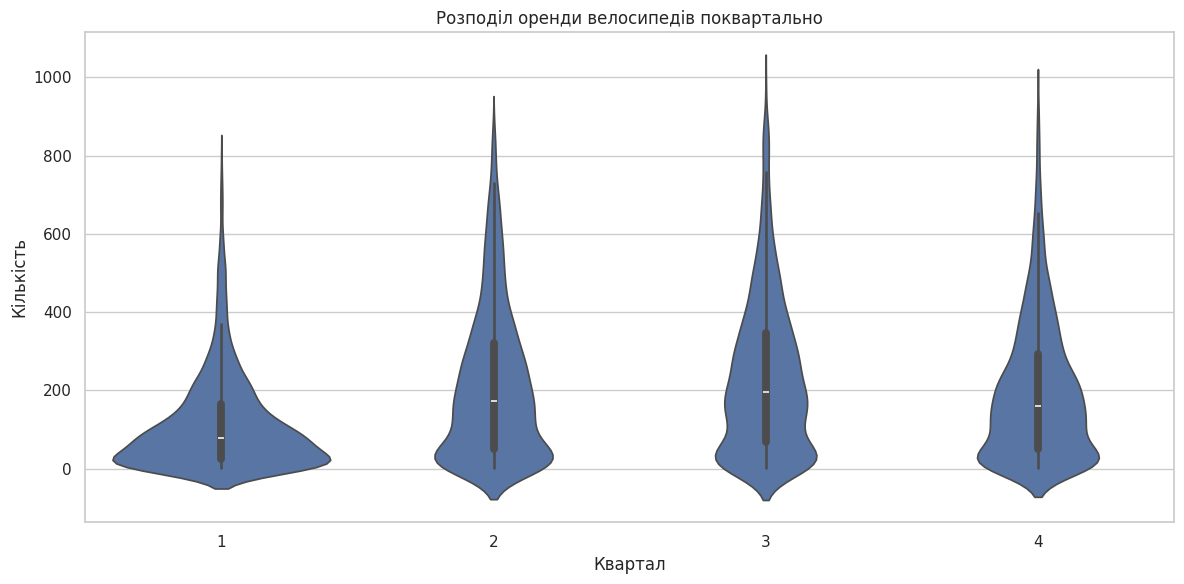

In [12]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='season', y='count')
plt.title('Розподіл оренди велосипедів поквартально')
plt.xlabel('Квартал')
plt.ylabel('Кількість')
plt.tight_layout()
plt.show()

Що показує «товщина» violin plot?
Це щільність розподілу даних. Чим ширша частина графіку, тим більша концентрація значень у цьому діапазоні.

В якому кварталі найбільша варіабельність оренди?
У тому, де скрипка має найбільший розмах по вертикалі та найширша, як бачимо це літній або теплий сезон 3-й квартал, де і розкид значень найбільший, і максимальні піки оренди.

Яка перевага violin plot над звичайним box plot?
Box plot показує лише ключові статистичні точки, а violin plot повністю відображає форму та розподіл даних, поєднуючи в собі і бокс плот і оцінку щільності.

## Завдання 6 : Pairplot для мультиваріативного аналізу

**Завдання:**
Створіть pairplot для аналізу взаємозв'язків між ключовими змінними `'temp', 'humidity', 'windspeed', 'count'` . В якості візуальної розбивки за категоріями (параметр `hue`) додайте season (квартал).

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Між якими змінними спостерігається найсильніший лінійний зв'язок?
2. Яка характеристика найбільше відрізняється між кварталами?

In [13]:
df.shape

(10886, 21)

In [14]:
df.sample(frac=0.1).shape

(1089, 21)

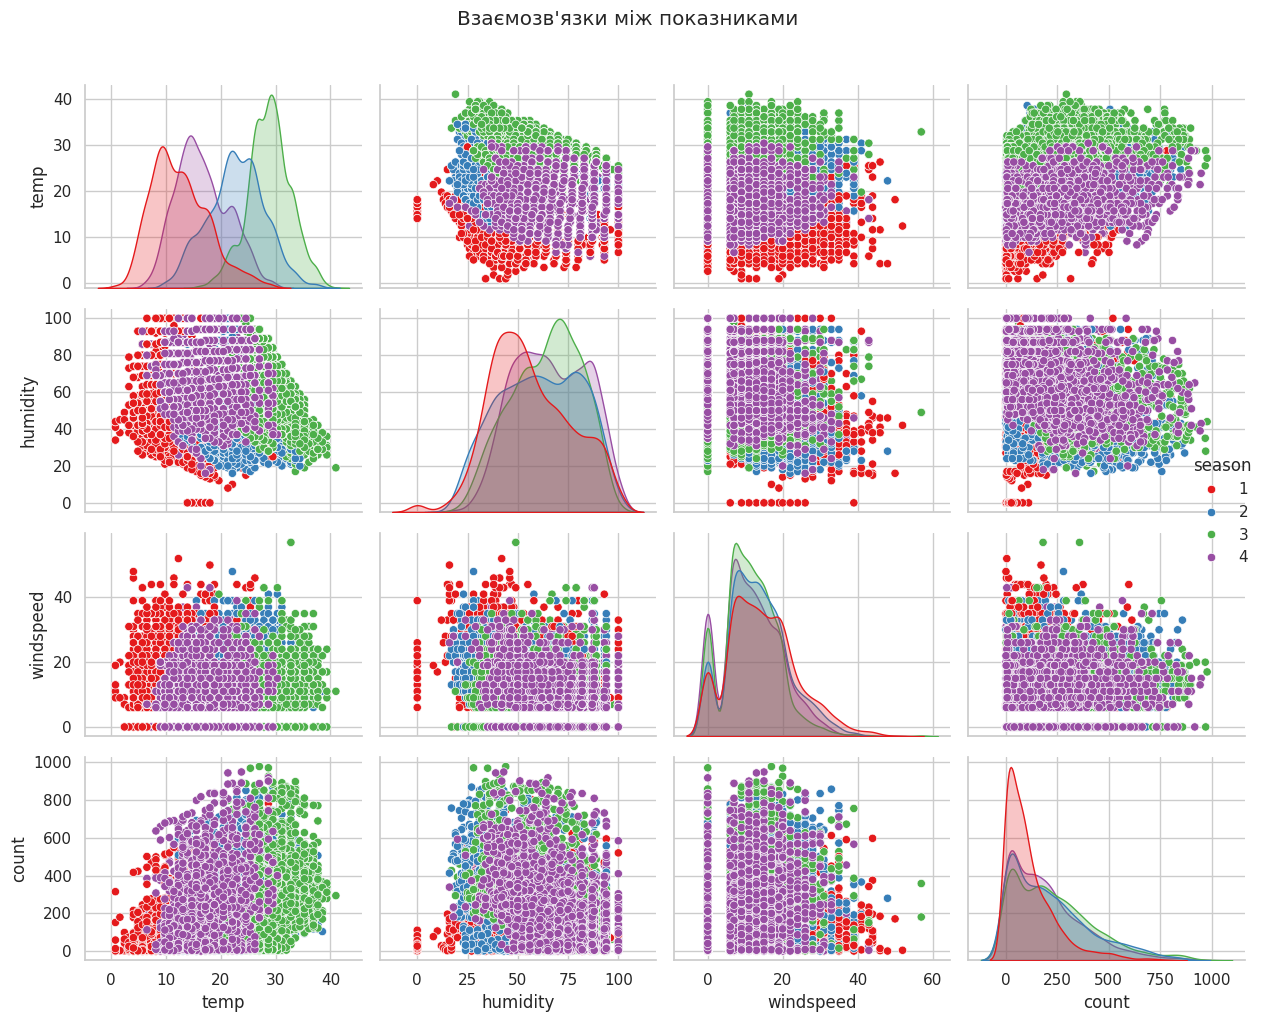

In [15]:
sample_df = df[['temp', 'humidity', 'windspeed', 'count', 'season']]
sns.pairplot(sample_df, hue='season',palette='Set1', height=2.5, aspect=1.2)
plt.suptitle('Взаємозв\'язки між показниками', y=1.02)
plt.tight_layout()
plt.show()

Найсильніший зв'язок на графіках простежується між temp та count, тобто зростання температури чітко супроводжується збільшенням кількості оренд, а також між самими показниками температури.
Найбільш помітно між кварталами відрізняється температура і загальна кількість оренд, графіки зміщуються діагонально, різні кольори розмежовані за температурними показниками.

## Завдання 7: Joint Plot для детального аналізу двох змінних

**Завдання:**
Проаналізуйте залежність між температурою та орендою за допомогою joint plot. В якості візуальної розбивки за категоріями (параметр `hue`) додайте `workingday`.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показують графіки по краях?
2. Чи є різниця у поведінці користувачів у робочий і неробочий день?

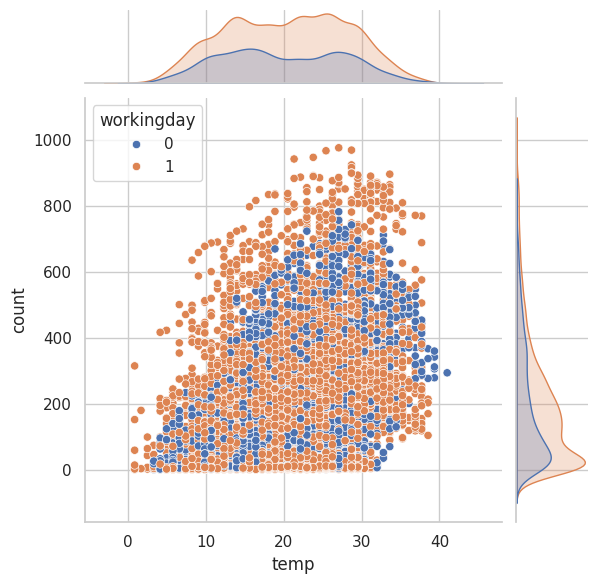

In [16]:
sns.jointplot(data=df, x="temp", y="count", hue="workingday");

Графіки по краях показують одномірні розподіли для кожної зі змінної окремо. Верхній графік відображає розподіл температури, а правий відображає розподіл кількості оренд із розбивкою на робочі та неробочі дні.
На рівні температурних діапазонів різниця мінімальна, але графіки щільності кількості оренд праворуч та розташування точок демонструють певні відмінності у використанні сервісу залежно від того чи робочий день чи вихідний.